# Caso 1 · Cauce: clasificación automática de mensajes de clientes

**Equipo:** _completar nombres_

Este notebook sigue las consignas del enunciado (pasos 1 a 20). Cada paso tiene su celda; agreguen todas las que necesiten.
Las funciones de `src/` se completan en los archivos `.py`, no en el notebook. Antes de entregar: *Reiniciar y ejecutar todo*.

In [5]:
%load_ext autoreload
%autoreload 2
# autoreload vuelve a cargar los módulos de src/ cada vez que los modifican, sin reiniciar el notebook.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42

from src.limpieza import limpiar_texto
from src.naive_bayes import NaiveBayesMultinomial, terminos_mas_indicativos
from src.derivacion import REVISION, derivar, evaluar_derivacion

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Estado de las pruebas automáticas
Ejecuten esta celda cada vez que terminen una función de `src/`.

In [6]:
!python -m pytest -q --tb=no -rf

...............................                                          [100%]
31 passed in 4.37s


## Parte A · Exploración y línea base

**Paso 1.** Carguen `datos/mensajes_historicos.csv` e informen filas, nulos, mensajes vacíos, duplicados (mismo `id_cliente` y mismo `texto`), distribución de `equipo_final`, distribución por canal y cantidad de palabras por clase.

In [7]:
# Tu código aquí
df = pd.read_csv("datos/mensajes_historicos.csv")
df_tv = (df["texto"].str.strip() == "").sum()
df_null = df["texto"].isnull().sum()
df_dup = df.duplicated(subset=["texto", "id_cliente"]).sum()



print(f"Cantidad de mensajes vacíos: {df_tv}")
print(f"Cantidad de mensajes con valor nulo: {df_null}")
print(f"Cantidad de mensajes duplicados por clientes: {df_dup}")


Cantidad de mensajes vacíos: 7
Cantidad de mensajes con valor nulo: 11
Cantidad de mensajes duplicados por clientes: 200


In [8]:
df["cantidad_palabras"] = df["texto"].fillna("").apply(lambda texto: len(texto.split()))

df[["texto", "equipo_final", "cantidad_palabras"]].head()

,texto,equipo_final,cantidad_palabras
0,?,transferencias,1
1,buenas noches está bloqueada la cuenat después...,cuenta_acceso,13
2,"hola, como estan? como hago para acreditar la ...",transferencias,23
3,"hola, como estan? como hago para acreditar la ...",transferencias,23
4,"hola buenas, necesito modificar la dirección d...",tarjeta,15


In [9]:
df["equipo_final"].value_counts()
print(f"Cantidad de mensajes por equipo: {df['equipo_final'].value_counts()}")
df["canal"].value_counts()
print(f"\nCantidad de mensajes por canal: {df['canal'].value_counts()} ")

Cantidad de mensajes por equipo: equipo_final
transferencias           2552
tarjeta                  2057
cuenta_acceso            1648
prestamos_inversiones    1029
fraude                    914
Name: count, dtype: int64

Cantidad de mensajes por canal: canal
app_chat          3676
whatsapp          2499
email             1163
formulario_web     862
Name: count, dtype: int64 


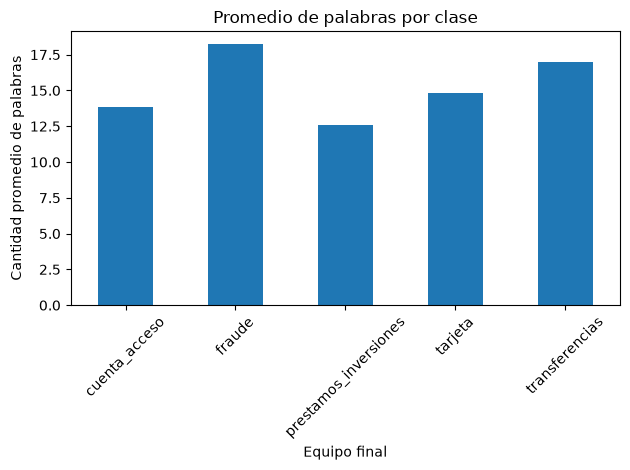

In [10]:
promedio_palabras = df.groupby("equipo_final")["cantidad_palabras"].mean()

promedio_palabras.plot(kind="bar")

plt.title("Promedio de palabras por clase")
plt.xlabel("Equipo final")
plt.ylabel("Cantidad promedio de palabras")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Paso 2.** Línea base de la mesa de entrada (`equipo_derivado` contra `equipo_final`): exactitud, F1 macro, matriz de confusión normalizada por fila y porcentaje de fraude derivado a otro equipo.

Exactitud de la mesa de entrada: 0.826  (error: 0.174)
F1 macro:                        0.817
Fraude derivado a otro equipo:   31.7%


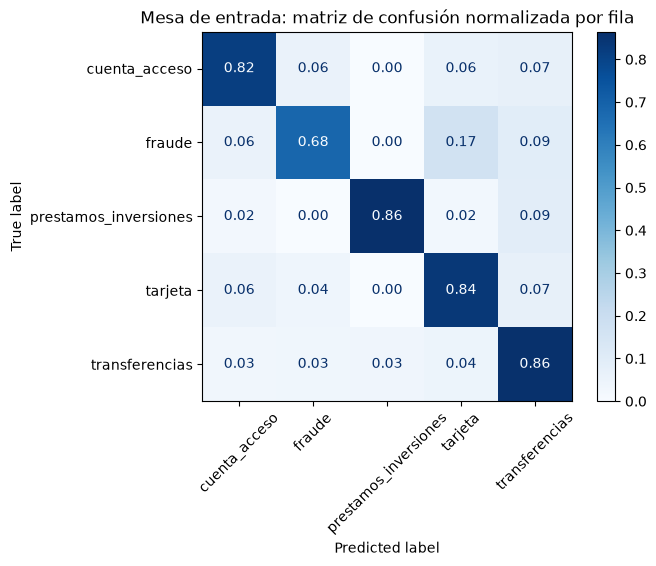

In [11]:
# Tu código aquí
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

EQUIPOS = sorted(df["equipo_final"].unique())

acc_mesa = accuracy_score(df["equipo_final"], df["equipo_derivado"])
f1_mesa = f1_score(df["equipo_final"], df["equipo_derivado"], average="macro")
es_fraude = df["equipo_final"] == "fraude"
fraude_a_otro = (df.loc[es_fraude, "equipo_derivado"] != "fraude").mean()

print(f"Exactitud de la mesa de entrada: {acc_mesa:.3f}  (error: {1 - acc_mesa:.3f})")
print(f"F1 macro:                        {f1_mesa:.3f}")
print(f"Fraude derivado a otro equipo:   {fraude_a_otro:.1%}")

cm = confusion_matrix(df["equipo_final"], df["equipo_derivado"], labels=EQUIPOS, normalize="true")
ConfusionMatrixDisplay(cm, display_labels=EQUIPOS).plot(cmap="Blues", values_format=".2f", xticks_rotation=45)
plt.title("Mesa de entrada: matriz de confusión normalizada por fila"); plt.show()

**Paso 3.** Eliminen los duplicados conservando el primero y expliquen por qué se hace antes de dividir.

In [12]:
# Tu código aquí
n_antes = len(df)
df = df.drop_duplicates(subset=["id_cliente", "texto"], keep="first").reset_index(drop=True)
print(f"Filas antes: {n_antes} | después: {len(df)} | eliminadas: {n_antes - len(df)}")

Filas antes: 8200 | después: 8000 | eliminadas: 200


## Parte B · Limpieza de texto (`src/limpieza.py`)

**Paso 4.** Implementen `quitar_tildes` y `limpiar_texto` en `src/limpieza.py` hasta que pasen `tests/test_limpieza.py`. Muestren aquí 5 ejemplos de texto original y limpio.

In [29]:
# Tu código aquí
# Los tests se corren en la celda "Estado de las pruebas automáticas" (más arriba).
ejemplos = df["texto"].sample(5, random_state=SEMILLA)
for original in ejemplos:
    print("ORIGINAL:", original)
    print("LIMPIO:  ", limpiar_texto(original))
    print()

ORIGINAL: buenas solicité la tarjeta física hace varios días y el seguimiento no avanza necesito una solución ya
LIMPIO:   buenas solicite la tarjeta fisica hace varios dias y el seguimiento no avanza necesito una solucion ya

ORIGINAL: buenas noches no pueod validar la selfie estoy de viaje gracias!!
LIMPIO:   buenas noches no pueod validar la selfie estoy de viaje gracias

ORIGINAL: hola, como estan? me robaron la plata de la cuenta, nadie me responde necesito una solucion ya
LIMPIO:   hola como estan me robaron la plata de la cuenta nadie me responde necesito una solucion ya

ORIGINAL: Buenas tardes, Deposité dinero en efectivo en un corresponsal y no se ve reflejado el martes. Aguardo respuesta. María González
LIMPIO:   buenas tardes deposite dinero en efectivo en un corresponsal y no se ve reflejado el martes aguardo respuesta maria gonzalez

ORIGINAL: buenas noches, se bloqueo la tarjeta por poner mal el PIN varias veces necesito la plata para hoy urgente
LIMPIO:   buenas noches 

**Paso 5.** Creen la columna `texto_limpio`. Los mensajes con menos de dos palabras se excluyen del entrenamiento y van a revisión humana: ¿cuántos son y qué contienen?

In [30]:
# Tu código aquí
df["texto_limpio"] = df["texto"].apply(limpiar_texto)
df["n_palabras"] = df["texto_limpio"].str.split().str.len()

cortos = df[df["n_palabras"] < 2]
print(f"Mensajes con menos de 2 palabras: {len(cortos)} ({len(cortos) / len(df):.1%})")
print("\nQué contienen (texto limpio más frecuente):")
display(cortos["texto_limpio"].value_counts().head(15).to_frame("veces"))
print("A qué equipo iban realmente:")
display(cortos["equipo_final"].value_counts().to_frame("mensajes"))

# Estos mensajes no se usan para entrenar ni evaluar: en producción van a revisión humana.
df_modelo = df[df["n_palabras"] >= 2].reset_index(drop=True)
PROP_CORTOS = len(cortos) / len(df)
print(f"\nMensajes para modelar: {len(df_modelo)}")

Mensajes con menos de 2 palabras: 70 (0.9%)

Qué contienen (texto limpio más frecuente):


,veces
texto_limpio,
,48
hola,15
ok,7


A qué equipo iban realmente:


,mensajes
equipo_final,
tarjeta,18
transferencias,16
cuenta_acceso,16
prestamos_inversiones,14
fraude,6



Mensajes para modelar: 7930


## Parte C · Naive Bayes desde cero (`src/naive_bayes.py`)

**Paso 6.** Implementen `log_suma_exp`, `NaiveBayesMultinomial` y `terminos_mas_indicativos` hasta que pasen `tests/test_naive_bayes.py`.

In [31]:
# Tu código aquí
# Prueba rápida con datos de juguete (las pruebas completas están en tests/test_naive_bayes.py)
from sklearn.feature_extraction.text import CountVectorizer
docs = ["gana dinero gratis", "premio gratis ya", "reunion manana", "informe de la reunion"]
etq = ["spam", "spam", "normal", "normal"]
v = CountVectorizer(); Xj = v.fit_transform(docs)
m = NaiveBayesMultinomial(alpha=1.0).fit(Xj, etq)
print(m.classes_, m.predict(v.transform(["premio gratis"])))
print(m.predict_proba(v.transform(["premio gratis"])).round(3))
print(terminos_mas_indicativos(m, v.get_feature_names_out(), n=3))

['normal' 'spam'] ['spam']
[[0.143 0.857]]
{np.str_('normal'): ['reunion', 'manana', 'informe'], np.str_('spam'): ['gratis', 'ya', 'gana']}


**Paso 7.** División 80/20 estratificada por `equipo_final` con `random_state=42`.

In [32]:
# Tu código aquí
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df_modelo, test_size=0.2, stratify=df_modelo["equipo_final"], random_state=SEMILLA)

X_train_txt, y_train = train_df["texto_limpio"], train_df["equipo_final"]
X_test_txt, y_test = test_df["texto_limpio"], test_df["equipo_final"]

print(f"Entrenamiento: {len(train_df)} | Prueba: {len(test_df)}")
display(pd.DataFrame({
    "train %": y_train.value_counts(normalize=True).round(3),
    "test %": y_test.value_counts(normalize=True).round(3)}))

Entrenamiento: 6344 | Prueba: 1586


,train %,test %
equipo_final,,
transferencias,0.311,0.311
tarjeta,0.252,0.252
cuenta_acceso,0.201,0.201
prestamos_inversiones,0.125,0.125
fraude,0.111,0.111


**Paso 8.** `CountVectorizer` + su clase y la de scikit-learn con `alpha=1`: muestren que predicen lo mismo en el 100% de los mensajes de prueba.

In [33]:
# Tu código aquí
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

vec = CountVectorizer()
X_train = vec.fit_transform(X_train_txt)   # el vocabulario se aprende SOLO con entrenamiento
X_test = vec.transform(X_test_txt)

nb_propio = NaiveBayesMultinomial(alpha=1.0).fit(X_train, y_train)
nb_sk = MultinomialNB(alpha=1.0).fit(X_train, y_train)

pred_propio = nb_propio.predict(X_test)
pred_sk = nb_sk.predict(X_test)

coinciden = (pred_propio == pred_sk).mean()
dif_proba = np.abs(nb_propio.predict_proba(X_test) - nb_sk.predict_proba(X_test)).max()
print(f"Coincidencia de predicciones: {coinciden:.1%}")

Coincidencia de predicciones: 100.0%


**Paso 9.** Los 10 términos más indicativos de cada clase y su interpretación para el negocio.

In [34]:
# Tu código aquí
indicativos = terminos_mas_indicativos(nb_propio, vec.get_feature_names_out(), n=10)
display(pd.DataFrame(indicativos))

,cuenta_acceso,fraude,prestamos_inversiones,tarjeta,transferencias
0,actualizar,robaron,preaprobado,cajero,transferir
1,nuevo,diciendo,las,virtual,acredito
2,validar,yo,cuotas,entrega,limite
3,reconoce,reconozco,ahorros,nueva,qr
4,contrasena,pidiendo,invertir,solo,corresponsal
5,entrar,ahora,punitorios,insertandola,transferencia
6,modifico,son,vi,fisica,deposite
7,validacion,mios,invierto,acerco,programada
8,token,aparecen,pagos,correo,equivocada
9,ingresar,nombre,conviene,contactless,diario


## Parte D · Ajuste y comparación con KNN

**Paso 10.** `GridSearchCV` del pipeline `CountVectorizer` + `NaiveBayesMultinomial` (5 particiones estratificadas, `f1_macro`). Conclusión sobre cada hiperparámetro.

In [ ]:
# Tu código aquí
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

pipe_nb = Pipeline([("vec", CountVectorizer()), ("nb", NaiveBayesMultinomial())])
grid_nb = {
    "vec__ngram_range": [(1, 1), (1, 2)],
    "vec__min_df": [2, 3, 5],
    "nb__alpha": [0.01, 0.1, 0.5, 1.0],
}
# Nota: NaiveBayesMultinomial pasa a matriz densa al predecir; con vocabularios enormes
gs_nb = GridSearchCV(pipe_nb, grid_nb, cv=cv, scoring="f1_macro", n_jobs=-1, refit=True)
gs_nb.fit(X_train_txt, y_train)

print("Mejores parámetros:", gs_nb.best_params_)
print(f"F1 macro (validación cruzada): {gs_nb.best_score_:.4f}")

res_nb = pd.DataFrame(gs_nb.cv_results_)
for p in grid_nb:
    print(f"\nEfecto de {p} (promedio de mean_test_score):")

Mejores parámetros: {'nb__alpha': 0.1, 'vec__min_df': 2, 'vec__ngram_range': (1, 2)}
F1 macro (validación cruzada): 0.9356

Efecto de vec__ngram_range (promedio de mean_test_score):

Efecto de vec__min_df (promedio de mean_test_score):

Efecto de nb__alpha (promedio de mean_test_score):


**Paso 11.** Misma búsqueda con `TfidfVectorizer` + `KNeighborsClassifier(metric="cosine", algorithm="brute")`. ¿Por qué coseno y no euclídea?

In [39]:
# Tu código aquí
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import KNeighborsClassifier

pipe_knn = Pipeline([
    ("vec", TfidfVectorizer()),
    ("knn", KNeighborsClassifier(metric="cosine", algorithm="brute")),
])
grid_knn = {
    "vec__ngram_range": [(1, 1), (1, 2)],
    "vec__min_df": [2, 3, 5],
    "knn__n_neighbors": [3, 5, 11, 21],
    "knn__weights": ["uniform", "distance"],
}
gs_knn = GridSearchCV(pipe_knn, grid_knn, cv=cv, scoring="f1_macro", n_jobs=-1, refit=True)
gs_knn.fit(X_train_txt, y_train)

print("Mejores parámetros:", gs_knn.best_params_)
print(f"F1 macro (validación cruzada): {gs_knn.best_score_:.4f}")

res_knn = pd.DataFrame(gs_knn.cv_results_)
for p in grid_knn:
    print(f"\nEfecto de {p}:")
    display(res_knn.groupby(f"param_{p}")["mean_test_score"].agg(["mean", "max"]).round(4))

c:\teccdeia\segundo\mineria de datos\Cauce_una_billetera_virtual_-Naive_Bayes-\env\Lib\site-packages\joblib\externals\loky\process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Mejores parámetros: {'knn__n_neighbors': 11, 'knn__weights': 'distance', 'vec__min_df': 2, 'vec__ngram_range': (1, 2)}
F1 macro (validación cruzada): 0.9304

Efecto de vec__ngram_range:


,mean,max
param_vec__ngram_range,,
"(1, 1)",0.9197,0.9259
"(1, 2)",0.9261,0.9304



Efecto de vec__min_df:


,mean,max
param_vec__min_df,,
2,0.9229,0.9304
3,0.9233,0.9300
5,0.9223,0.9290



Efecto de knn__n_neighbors:


,mean,max
param_knn__n_neighbors,,
3,0.9174,0.9234
5,0.9228,0.9271
11,0.9254,0.9304
21,0.9259,0.9284



Efecto de knn__weights:


,mean,max
param_knn__weights,,
distance,0.9232,0.9304
uniform,0.9226,0.9290


**Paso 12.** Tiempo de predicción de 1.000 mensajes con 25%, 50%, 75% y 100% del entrenamiento, para los dos modelos. Gráfico y explicación.

,Naive Bayes,KNN
25%,0.0413,0.0651
50%,0.0425,0.0848
75%,0.0529,0.1231
100%,0.0541,0.1522


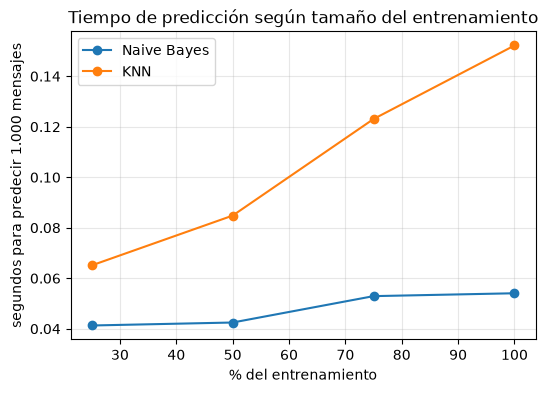

In [40]:
# Tu código aquí
import time
from sklearn.base import clone

rng = np.random.default_rng(SEMILLA)
idx_1000 = rng.choice(len(X_test_txt), size=1000, replace=len(X_test_txt) < 1000)
lote = X_test_txt.iloc[idx_1000]

fracciones = [0.25, 0.50, 0.75, 1.00]
tiempos = {"Naive Bayes": [], "KNN": []}
for f in fracciones:
    if f < 1.0:
        sub_X, _, sub_y, _ = train_test_split(
            X_train_txt, y_train, train_size=f, stratify=y_train, random_state=SEMILLA)
    else:
        sub_X, sub_y = X_train_txt, y_train
    for nombre, gs in [("Naive Bayes", gs_nb), ("KNN", gs_knn)]:
        modelo = clone(gs.best_estimator_).fit(sub_X, sub_y)
        medidas = []
        for _ in range(3):                      # nos quedamos con el mejor de 3 intentos
            t0 = time.perf_counter()
            modelo.predict(lote)
            medidas.append(time.perf_counter() - t0)
        tiempos[nombre].append(min(medidas))

df_t = pd.DataFrame(tiempos, index=[f"{int(f * 100)}%" for f in fracciones])
display(df_t.round(4))

plt.figure(figsize=(6, 4))
for nombre in tiempos:
    plt.plot([int(f * 100) for f in fracciones], tiempos[nombre], marker="o", label=nombre)
plt.xlabel("% del entrenamiento"); plt.ylabel("segundos para predecir 1.000 mensajes")
plt.title("Tiempo de predicción según tamaño del entrenamiento"); plt.legend(); plt.grid(alpha=.3); plt.show()

## Parte E · Regla de derivación y evaluación (`src/derivacion.py`)

**Paso 13.** Implementen `derivar` y `evaluar_derivacion` hasta que pasen `tests/test_derivacion.py`.

In [41]:
# Tu código aquí
# Prueba rápida de las dos funciones (las pruebas completas están en tests/test_derivacion.py)
clases_demo = ["cuentas", "fraude", "prestamos"]
proba_demo = np.array([[0.90, 0.05, 0.05],    # seguro -> cuentas
                       [0.30, 0.40, 0.30],    # sospecha de fraude -> fraude
                       [0.40, 0.10, 0.50]])   # duda -> revisión
dest = derivar(proba_demo, clases_demo, umbral_fraude=0.35, umbral_confianza=0.80)
print(dest)
print(evaluar_derivacion(np.array(["cuentas", "fraude", "prestamos"]), dest))

['cuentas' 'fraude' 'revision_humana']
{'cobertura': 0.6666666666666666, 'exactitud_automatica': 1.0, 'fraude_perdido': 0.0}


**Paso 14.** Probabilidades fuera de muestra con `cross_val_predict` y elección de los dos umbrales (con margen de seguridad) para Naive Bayes y para KNN.

In [42]:
# Tu código aquí

MAX_FRAUDE_PERDIDO = 0.02   # máximo de fraude derivado a otro equipo
MIN_EXACTITUD_AUTO = 0.95   # exactitud mínima de lo derivado automáticamente
MIN_COBERTURA      = 0.70   # cobertura mínima (el resto lo revisan personas)
# Margen de seguridad: exigimos cumplir con holgura en validación cruzada
# para no quedar justos cuando se evalúe en prueba.
MARGEN_FRAUDE = 0.80        # fraude_perdido <= 80% del máximo
MARGEN_EXACT  = 0.01        # exactitud >= mínimo + 1 punto

from sklearn.model_selection import cross_val_predict

modelos = {"Naive Bayes": gs_nb.best_estimator_, "KNN": gs_knn.best_estimator_}
CLASES = list(gs_nb.best_estimator_.named_steps["nb"].classes_)

# Probabilidades fuera de muestra: cada mensaje se predice con un modelo que NO lo vio.
proba_oof = {}
for nombre, est in modelos.items():
    proba_oof[nombre] = cross_val_predict(clone(est), X_train_txt, y_train, cv=cv, method="predict_proba")

def buscar_umbrales(proba, y_real):
    filas = []
    for uf in np.round(np.arange(0.10, 0.91, 0.05), 2):
        for uc in np.round(np.arange(0.50, 1.00, 0.05), 2):
            ind = evaluar_derivacion(y_real, derivar(proba, CLASES, uf, uc))
            filas.append({"umbral_fraude": uf, "umbral_confianza": uc, **ind})
    return pd.DataFrame(filas)

umbrales = {}
for nombre in modelos:
    grilla = buscar_umbrales(proba_oof[nombre], y_train.values)
    ok = grilla[(grilla["fraude_perdido"] <= MAX_FRAUDE_PERDIDO * MARGEN_FRAUDE)
                & (grilla["exactitud_automatica"] >= MIN_EXACTITUD_AUTO + MARGEN_EXACT)]
    if ok.empty:
        print(f"{nombre}: ninguna combinación cumple con margen; se usa la de menor fraude perdido.")
        elegido = grilla.sort_values(["fraude_perdido", "exactitud_automatica"], ascending=[True, False]).iloc[0]
    else:
        elegido = ok.sort_values("cobertura", ascending=False).iloc[0]   # la que automatiza más
    umbrales[nombre] = (float(elegido["umbral_fraude"]), float(elegido["umbral_confianza"]))
    print(f"{nombre}: umbral_fraude={umbrales[nombre][0]}, umbral_confianza={umbrales[nombre][1]}")
    print(elegido[["cobertura", "exactitud_automatica", "fraude_perdido"]].round(4).to_dict())

Naive Bayes: ninguna combinación cumple con margen; se usa la de menor fraude perdido.
Naive Bayes: umbral_fraude=0.9, umbral_confianza=0.95
{'cobertura': 0.962, 'exactitud_automatica': 0.9644, 'fraude_perdido': 0.0537}
KNN: ninguna combinación cumple con margen; se usa la de menor fraude perdido.
KNN: umbral_fraude=0.65, umbral_confianza=0.95
{'cobertura': 0.6379, 'exactitud_automatica': 0.9822, 'fraude_perdido': 0.0226}


**Paso 15.** Evaluación única en prueba: tabla con los cinco indicadores de aceptación para Naive Bayes, KNN y la mesa de entrada; reporte de clasificación y matriz de confusión del modelo elegido.

In [45]:
# Tu código aquí
from sklearn.metrics import classification_report

def indicadores(y_real, destino):
    y_real, destino = np.asarray(y_real), np.asarray(destino)
    ind = evaluar_derivacion(y_real, destino)
    # Indicadores extra de fraude (ajustá la tabla a los cinco del enunciado)
    ind["recall_fraude"] = float(np.mean(destino[y_real == "fraude"] == "fraude"))
    a_fraude = destino == "fraude"
    ind["precision_fraude"] = float(np.mean(y_real[a_fraude] == "fraude")) if a_fraude.any() else 0.0
    return ind

filas, destinos_test, proba_test = {}, {}, {}
for nombre, est in modelos.items():
    final = clone(est).fit(X_train_txt, y_train)                 # entrenado solo con train
    proba_test[nombre] = final.predict_proba(X_test_txt)
    uf, uc = umbrales[nombre]
    destinos_test[nombre] = derivar(proba_test[nombre], CLASES, uf, uc)
    filas[nombre] = indicadores(y_test, destinos_test[nombre])

filas["Mesa de entrada"] = indicadores(y_test, test_df["equipo_derivado"].values)
tabla = pd.DataFrame(filas).T
display(tabla.round(4))

cumple = pd.DataFrame({
    "fraude_perdido": tabla["fraude_perdido"] <= MAX_FRAUDE_PERDIDO,
    "exactitud_auto": tabla["exactitud_automatica"] >= MIN_EXACTITUD_AUTO,
    "cobertura": tabla["cobertura"] >= MIN_COBERTURA,
})
display(cumple)

# ----- Modelo elegido: entre los que cumplen los criterios, el de mayor cobertura -----
# (si ninguno cumple, el de menor fraude perdido). Podés fijarlo a mano: ELEGIDO = "Naive Bayes"
candidatos = cumple.loc[["Naive Bayes", "KNN"]].all(axis=1)
if candidatos.any():
    ELEGIDO = tabla.loc[candidatos[candidatos].index, "cobertura"].idxmax()
else:
    ELEGIDO = tabla.loc[["Naive Bayes", "KNN"], "fraude_perdido"].idxmin()
    print("Ningún modelo cumple todos los criterios; se elige el de menor fraude perdido.")
destino_elegido = destinos_test[ELEGIDO]
print(f"\nModelo elegido: {ELEGIDO}\n")
print(classification_report(y_test, modelos[ELEGIDO].predict(X_test_txt), zero_division=0))

cm = pd.crosstab(y_test.values, destino_elegido, normalize="index").round(3)
cm.index.name, cm.columns.name = "real", "destino"
print("Real vs destino (proporción por fila; revision_humana = la revisa una persona):")
display(cm)

,cobertura,exactitud_automatica,fraude_perdido,recall_fraude,precision_fraude
Naive Bayes,0.9628,0.9620,0.0341,0.8977,0.9576
KNN,0.6841,0.9853,0.0284,0.8182,0.9863
Mesa de entrada,1.0000,0.8354,0.3352,0.6648,0.7358


,fraude_perdido,exactitud_auto,cobertura
Naive Bayes,False,True,True
KNN,False,True,False
Mesa de entrada,False,False,True


Ningún modelo cumple todos los criterios; se elige el de menor fraude perdido.

Modelo elegido: KNN

                       precision    recall  f1-score   support

        cuenta_acceso       0.92      0.93      0.92       318
               fraude       0.94      0.86      0.90       176
prestamos_inversiones       0.96      0.92      0.94       198
              tarjeta       0.90      0.95      0.92       400
       transferencias       0.94      0.93      0.94       494

             accuracy                           0.93      1586
            macro avg       0.93      0.92      0.92      1586
         weighted avg       0.93      0.93      0.93      1586

Real vs destino (proporción por fila; revision_humana = la revisa una persona):


destino,cuenta_acceso,fraude,prestamos_inversiones,revision_humana,tarjeta,transferencias
real,,,,,,
cuenta_acceso,0.594,0.000,0.003,0.403,0.000,0.000
fraude,0.011,0.818,0.000,0.153,0.006,0.011
prestamos_inversiones,0.010,0.005,0.596,0.379,0.010,0.000
tarjeta,0.005,0.000,0.000,0.280,0.712,0.002
transferencias,0.000,0.002,0.002,0.322,0.000,0.674


**Paso 16.** Análisis de 10 errores de derivación automática: causa de cada uno y una mejora concreta.

In [25]:
# Tu código aquí

**Paso 17.** Impacto en un día de 6.500 mensajes.

In [26]:
# Tu código aquí

## Parte F · Predicción de los mensajes nuevos

**Paso 18.** Reentrenen el modelo elegido con todos los mensajes históricos limpios y apliquen la regla a `datos/mensajes_nuevos.csv`.

In [27]:
# Tu código aquí

**Paso 19.** Generen `predicciones_caso1.csv` (2.040 filas; columnas `id_mensaje`, `equipo_predicho`, `prob_max`, `prob_fraude`, `derivacion`) y verifiquen el formato.

In [28]:
# Tu código aquí

## Parte G · Informe ejecutivo

**Paso 20.** El informe para Laura Benítez se entrega aparte, en `informe_ejecutivo.pdf`.

## Preguntas de reflexión profesional

Respondan cada pregunta en un párrafo, apoyándose en sus resultados.

**1. Naive Bayes supone que las palabras son independientes dada la clase. ¿Por qué clasifica bien igual? ¿Qué consecuencia tiene esa suposición sobre las probabilidades?**

_Respuesta:_ 

**2. ¿Qué pasaría con `alpha=0` si aparece una palabra que nunca se vio en la clase `fraude`?**

_Respuesta:_ 

**3. ¿Por qué `equipo_derivado` no puede usarse como variable del modelo?**

_Respuesta:_ 

**4. ¿Qué costo tendría KNN en producción comparado con Naive Bayes? ¿En qué situación elegirían KNN igual?**

_Respuesta:_ 

**5. ¿Quién debería fijar el máximo de fraude perdido y la exactitud mínima? ¿Qué información tiene que llevar el equipo de datos?**

_Respuesta:_ 

**6. Si Cauce lanza un seguro para celulares, ¿qué le pasa al modelo y cómo lo detectarían en producción?**

_Respuesta:_ 

**7. ¿Qué datos personales anonimizarían antes de guardar los datos de entrenamiento y cómo afectaría al modelo?**

_Respuesta:_ 